---
title: "3.4.b Amenaza por calor extremo"
short_title: "b. Amenaza"
subtitle: "Tendencias de temperatura, días y olas de calor, temperatura aparente e isla de calor urbana"
description: "Análisis de la amenaza por calor en Leticia con ERA5 (1950–2026) y temperatura de superficie Landsat."
keywords: [calor, olas de calor, temperatura aparente, Landsat, LST, ERA5, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/34_calor/b_amenaza.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

En el trópico húmedo el calor se siente por la combinación de temperatura y humedad: con humedades del 80–90 %,
el cuerpo pierde poco calor por sudor. Por eso esta página mide la **temperatura máxima**, la **temperatura
aparente** (que integra humedad y viento) y los **días y olas de calor con umbrales relativos** al clima de
Leticia, siguiendo el flujo de olas de calor de CLIMAAX [@climaax2026handbook]. Al final, Landsat muestra
**dónde** hace más calor dentro de la ciudad.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import clima, espacial, fuentes, hidro, viz
from leticia.config import aoi_cfg, parametros

pc = parametros()["calor"]
base = tuple(aoi_cfg()["clima"]["periodo_base"])
era = fuentes.clima_diario()
tmax, tmin, tap = era["temperature_2m_max"], era["temperature_2m_min"], era["apparent_temperature_max"]

## 1. Calentamiento observado

Tendencia 1980–presente de la temperatura máxima: **+0.22 °C por década** (Mann-Kendall p = 0.000). Años más cálidos: 2005 (+0.81 °C), 2010 (+0.76 °C), 2024 (+0.76 °C), 2006 (+0.43 °C).

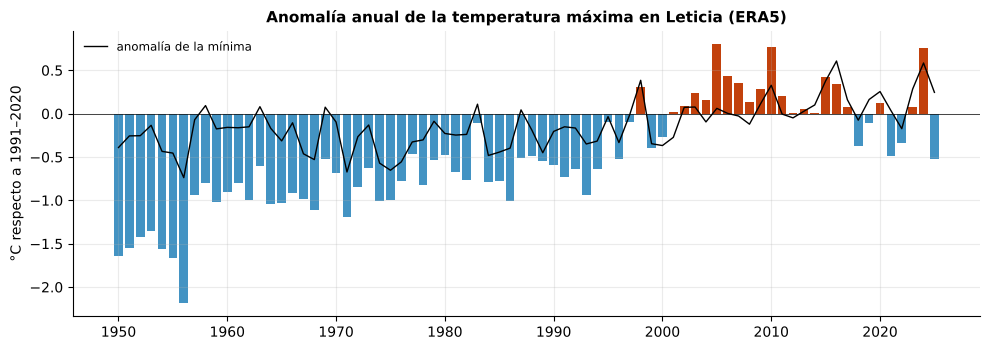

In [3]:
anom = clima.anomalia_anual(tmax[tmax.index.year < pd.Timestamp.today().year], base)
anom_min = clima.anomalia_anual(tmin[tmin.index.year < pd.Timestamp.today().year], base)
mk = hidro.mann_kendall(anom.loc[1980:])
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(anom.index, anom, color=np.where(anom > 0, viz.CALOR, "#4393c3"))
ax.plot(anom_min.index, anom_min, color="k", lw=1, label="anomalía de la mínima")
ax.axhline(0, color="k", lw=0.5)
ax.set_ylabel("°C respecto a 1991–2020")
ax.set_title("Anomalía anual de la temperatura máxima en Leticia (ERA5)")
ax.legend()
fig.tight_layout()
display(Markdown(f"Tendencia 1980–presente de la temperatura máxima: **{mk['sen']*10:+.2f} °C por década** (Mann-Kendall p = {mk['p']:.3f}). "
                 f"Años más cálidos: " + ", ".join(f"{a} ({v:+.2f} °C)" for a, v in anom.nlargest(4).items()) + "."))

In [4]:
viz.pie(viz.nota_fuente("clima_diario"))

*Fuente: ECMWF ERA5 (vía Open-Meteo) — Reanálisis ERA5, celda 0,25°.*

## 2. Días y olas de calor con umbral local

,dias_sobre_umbral,olas,ola_mas_larga
1950s,1.70,0.30,1.00
1960s,5.70,0.60,2.00
1970s,7.60,0.70,1.20
1980s,7.00,0.30,0.80
1990s,13.70,1.20,1.40
2000s,44.00,4.40,5.20
2010s,43.40,3.10,4.80
2020s,41.80,5.20,6.00


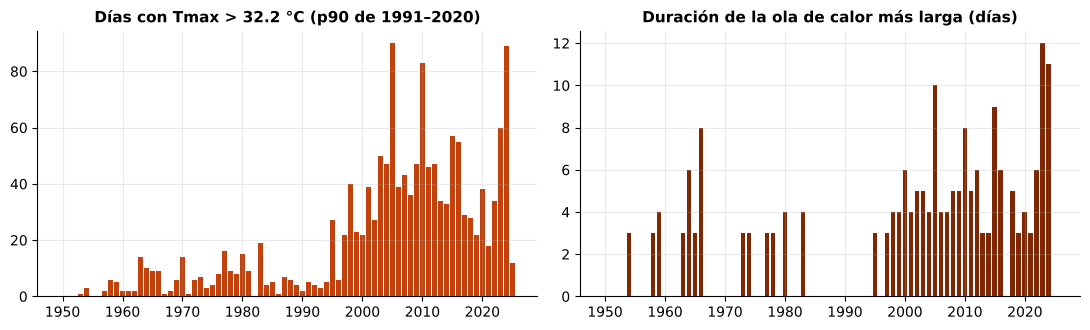

In [5]:
umbral = clima.umbral_percentil(tmax, pc["percentil_umbral"], base)
olas = clima.olas_calor(tmax, umbral, pc["dias_minimos_ola"])
olas = olas[olas.index < pd.Timestamp.today().year]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(olas.index, olas["dias_sobre_umbral"], color=viz.CALOR)
ax[0].set_title(f"Días con Tmax > {umbral:.1f} °C (p{pc['percentil_umbral']} de {base[0]}–{base[1]})")
ax[1].bar(olas.index, olas["ola_mas_larga"], color="#7f2704")
ax[1].set_title("Duración de la ola de calor más larga (días)")
fig.tight_layout()
dec = olas.groupby((olas.index // 10) * 10)[["dias_sobre_umbral", "olas", "ola_mas_larga"]].mean().round(1)
dec.index = [f"{d}s" for d in dec.index]
display(dec)

Por construcción, en 1991–2020 el 10 % de los días supera el umbral (~36 días por año). Lo que importa es lo que
pasa después: si los años recientes quedan muy por encima de esa línea de base, el clima de Leticia ya se desplazó
hacia lo cálido. Las cuatro olas de calor de 2023 en la Amazonía, de 2 a 5 °C sobre lo normal, coincidieron con
la sequía extrema [@costa2023spa; @espinoza2024].

## 3. Temperatura aparente: el calor que siente el cuerpo

,temperatura aparente máxima media (°C),días ≥ 41 °C (peligro)
time,,
1950s,35.00,0.00
1960s,35.60,0.60
1970s,35.70,1.20
1980s,36.20,2.70
1990s,36.50,8.70
2000s,37.30,23.00
2010s,37.10,20.30
2020s,36.40,15.30


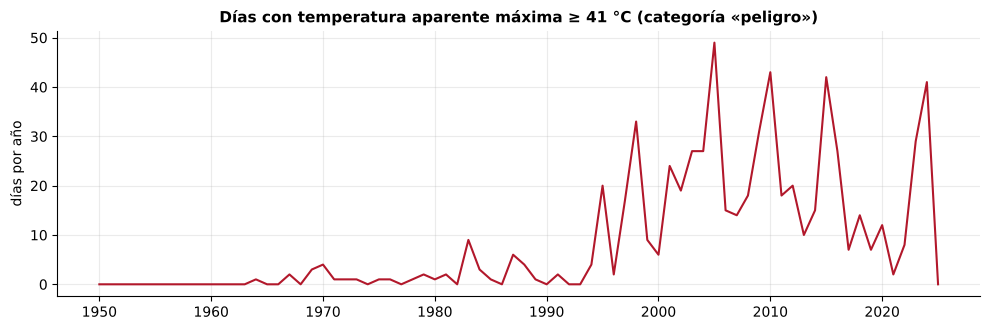

In [6]:
cat = pc["indice_calor_categorias"]
anual = pd.DataFrame({
    "temperatura aparente máxima media (°C)": tap.groupby(tap.index.year).mean(),
    f"días ≥ {cat['peligro']} °C (peligro)": (tap >= cat["peligro"]).groupby(tap.index.year).sum(),
})
anual = anual[anual.index < pd.Timestamp.today().year]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(anual.index, anual.iloc[:, 1], color=viz.ROJO, lw=1.5)
ax.set_ylabel("días por año")
ax.set_title(f"Días con temperatura aparente máxima ≥ {cat['peligro']} °C (categoría «peligro»)")
fig.tight_layout()
display(anual.groupby((anual.index // 10) * 10).mean().round(1).rename(index=lambda d: f"{d}s"))

La temperatura aparente de Open-Meteo sigue la fórmula de Steadman, con humedad, viento y radiación. En Leticia
supera los 32 °C casi todos los días del año, de modo que el umbral útil es el de «peligro» (≥ 41 °C) del índice
de calor del Servicio Meteorológico de EE. UU., que se usa aquí como referencia, no como umbrales de salud locales, que Colombia aún no ha definido
para la Amazonía. ERA5 representa una celda de ~28 km dominada por bosque, así que **subestima** el calor de la
ciudad construida.

## 4. ¿Dónde hace más calor dentro de Leticia? Temperatura de superficie

Mediana de **32 escenas** Landsat 8/9 de julio a octubre (2022–2024) con nubes enmascaradas. Correlación NDVI–temperatura de superficie entre píxeles de tierra: **r = -0.82**.

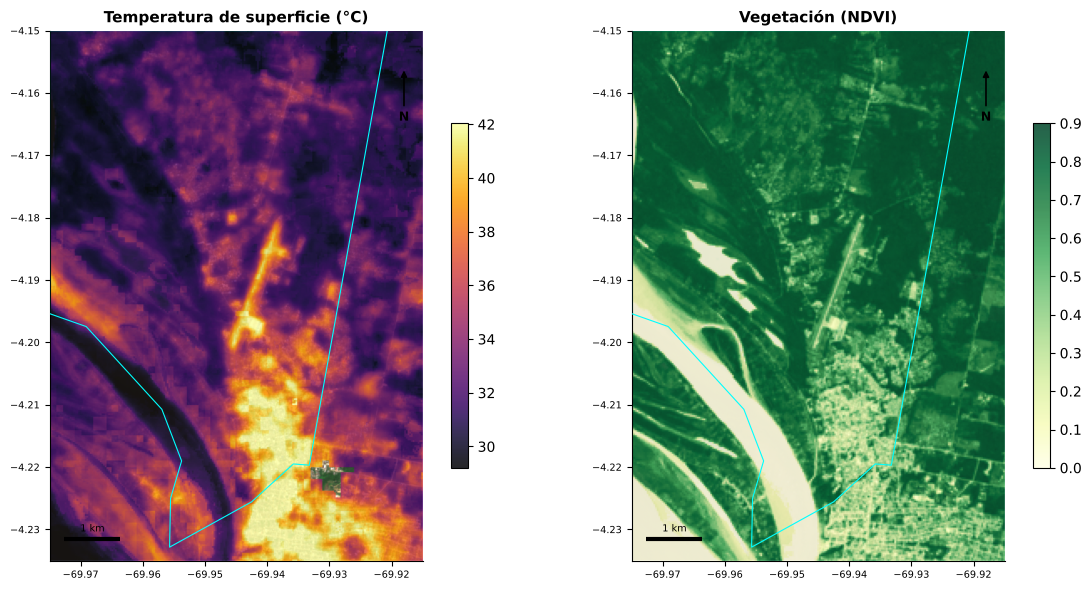

In [7]:
from leticia import aoi
lst = espacial.temperatura_superficie(2024, pc["meses_landsat"], nubes_max=pc["nubes_max"])
urbana = aoi.area_urbana().to_crs(4326)
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, var, cmap, titulo, lim in ((ax[0], "lst", "inferno", "Temperatura de superficie (°C)", None),
                                  (ax[1], "ndvi", "YlGn", "Vegetación (NDVI)", (0, 0.9))):
    d = lst[var]
    vmin, vmax = lim or (np.nanpercentile(d, 2), np.nanpercentile(d, 98))
    viz.fondo(a)
    im = a.imshow(d.values, extent=(float(d.x.min()), float(d.x.max()), float(d.y.min()), float(d.y.max())), cmap=cmap, vmin=vmin, vmax=vmax,
                  alpha=0.85, zorder=2)
    urbana.boundary.plot(ax=a, color="cyan", lw=0.8, zorder=3)
    fig.colorbar(im, ax=a, shrink=0.65)
    viz.marco(a, "bbox_urbano", titulo)
fig.tight_layout()
ok = np.isfinite(lst["lst"].values) & (lst["ndvi"].values > 0.2)    # solo tierra: el agua es fresca y sin vegetación
r = np.corrcoef(lst["ndvi"].values[ok], lst["lst"].values[ok])[0, 1]
display(Markdown(f"Mediana de **{lst.attrs['escenas']} escenas** Landsat 8/9 de julio a octubre (2022–2024) con nubes enmascaradas. "
                 f"Correlación NDVI–temperatura de superficie entre píxeles de tierra: **r = {r:.2f}**."))

In [8]:
viz.pie(viz.nota_fuente("landsat") + " Temperatura de superficie de la banda térmica (ST_B10) de Landsat Collection 2 Level-2.")

*Fuente: USGS / NASA (Microsoft Planetary Computer) — Landsat Collection 2 Level-2 (reflectancia y temperatura de superficie). Temperatura de superficie de la banda térmica (ST_B10) de Landsat Collection 2 Level-2.*

**Lectura.** La temperatura de superficie a media mañana es mucho mayor sobre techos de zinc, pavimentos y suelo
desnudo (pista del aeropuerto, barrios densos) que sobre el bosque y los humedales: la diferencia entre el centro
de Leticia y el bosque vecino supera los 10 °C. La correlación negativa con el NDVI en tierra confirma que **la
vegetación es el principal regulador del calor urbano**. No es la
temperatura del aire, pero ordena bien los lugares según su exposición al calor.